# Quanto rende la pubblicità?

*Metodi Matematici e Statistici per le Decisioni Economiche · A.A. 2026/27 · Lezione 2*

[![Apri in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/vincnardelli/msd/blob/main/codice/2/regressione_advertising.ipynb)

Il codice dietro le slide della lezione 2: tutti i numeri e i grafici vengono da qui.
`advertising.csv` contiene, per 200 mercati, il budget pubblicitario su TV, radio e giornali (`TV`, `radio`, `newspaper`, migliaia di \$) e le vendite (`sales`, migliaia di unità).
I modelli si stimano con `statsmodels`, che vuole una tabella pandas: la convertiamo con `.to_pandas()`.

In [1]:
import polars as pl
from plotnine import *
import statsmodels.formula.api as smf

In [2]:
adv = pl.read_csv("https://www.vincnardelli.com/msd/dati/advertising.csv")
adv.head()

TV,radio,newspaper,sales
f64,f64,f64,f64
230.1,37.8,69.2,22.1
44.5,39.3,45.1,10.4
17.2,45.9,69.3,9.3
151.5,41.3,58.5,18.5
180.8,10.8,58.4,12.9


### 1. La retta dei minimi quadrati: vendite e budget TV

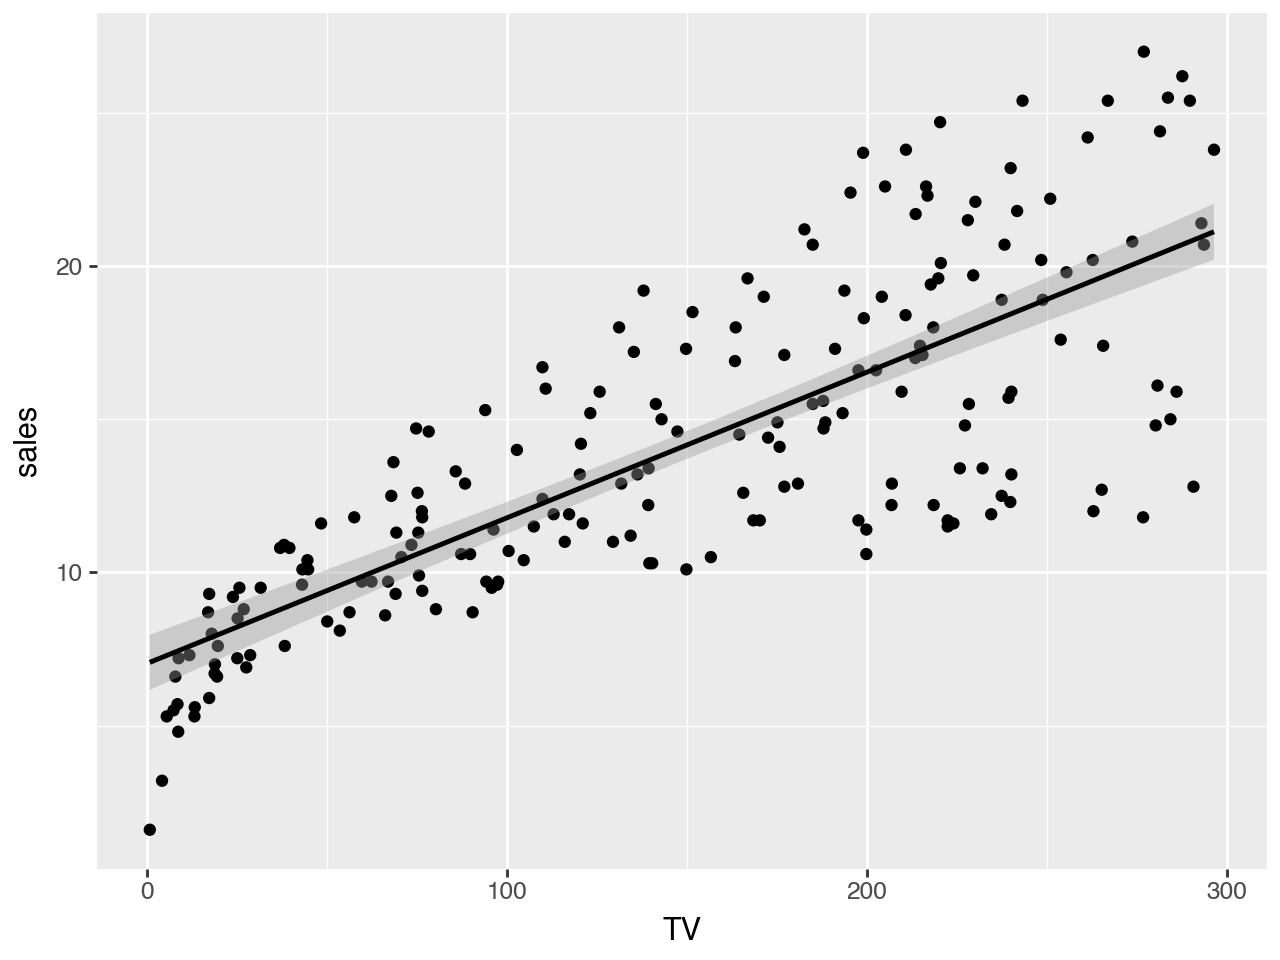

In [3]:
ggplot(adv, aes(x="TV", y="sales")) + geom_point() + geom_smooth(method="lm")

In [4]:
modello = smf.ols("sales ~ TV", data=adv.to_pandas()).fit()
modello.params

Intercept    7.032594
TV           0.047537
dtype: float64

### 2. La tabella dei risultati: errori standard, t, p-value, intervalli, $R^2$, RSE

In [5]:
modello.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  sales   R-squared:                       0.612
Model:                            OLS   Adj. R-squared:                  0.610
Method:                 Least Squares   F-statistic:                     312.1
Date:                Sun, 08 Nov 2026   Prob (F-statistic):           1.47e-42
Time:                        10:51:02   Log-Likelihood:                -519.05
No. Observations:                 200   AIC:                             1042.
Df Residuals:                     198   BIC:                             1049.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      7.0326      0.458     15.360      0.000       6.130       7.935
TV             0.0475      0.003     17.668      0.000       0.042       0.053
==============================================================================
Omnibus:                        0.531   Durbin-Watson:                   1.935
Prob(Omnibus):                  0.767   Jarque-Bera (JB):                0.669
Skew:                          -0.089   Prob(JB):                        0.716
Kurtosis:                       2.779   Cond. No.                         338.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [6]:
modello.conf_int()

,0,1
Intercept,6.129719,7.935468
TV,0.042231,0.052843


In [7]:
print("R2:", modello.rsquared)
print("RSE:", modello.scale ** 0.5)

R2: 0.6118750508500712
RSE: 3.258656368650462


In [8]:
# con una sola X, R2 è la correlazione al quadrato
adv.select(pl.corr("TV", "sales") ** 2)

TV
f64
0.611875


### 3. Prevedere, con i due intervalli: la media (`mean_ci`) e il singolo mercato (`obs_ci`)

In [9]:
modello.get_prediction({"TV": [0, 100, 200, 400]}).summary_frame(alpha=0.05)

,mean,mean_se,mean_ci_lower,mean_ci_upper,obs_ci_lower,obs_ci_upper
0,7.032594,0.457843,6.129719,7.935468,0.543349,13.521838
1,11.786258,0.262897,11.267820,12.304695,5.339251,18.233264
2,16.539922,0.270919,16.005665,17.074178,10.091624,22.988219
3,26.047250,0.718556,24.630244,27.464255,19.466747,32.627753


### 4. Altri dati, altra retta: la pendenza in 2.000 campioni simulati

In [10]:
import numpy as np
rng = np.random.default_rng(2026)
b0, b1 = modello.params
sigma = modello.scale ** 0.5
x = adv["TV"].to_numpy()
pendenze = []
for k in range(2000):
    y = b0 + b1 * x + rng.normal(0, sigma, len(x))   # nuovi mercati generati dal modello
    pendenze.append(np.polyfit(x, y, 1)[0])            # pendenza ristimata
print("deviazione standard delle pendenze:", np.std(pendenze))
print("errore standard dalla formula:     ", modello.bse["TV"])

deviazione standard delle pendenze: 0.0026598737956569107
errore standard dalla formula:      0.0026906071877968707


### 5. Tre regressioni semplici contro una multipla: il paradosso dei giornali

In [11]:
for x in ["TV", "radio", "newspaper"]:
    m = smf.ols(f"sales ~ {x}", data=adv.to_pandas()).fit()
    print(x, round(m.params[x], 4), round(m.pvalues[x], 4))

TV 0.0475 0.0
radio 0.2025 0.0
newspaper 0.0547 0.0011


In [12]:
multiplo = smf.ols("sales ~ TV + radio + newspaper", data=adv.to_pandas()).fit()
multiplo.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  sales   R-squared:                       0.897
Model:                            OLS   Adj. R-squared:                  0.896
Method:                 Least Squares   F-statistic:                     570.3
Date:                Sun, 08 Nov 2026   Prob (F-statistic):           1.58e-96
Time:                        10:51:02   Log-Likelihood:                -386.18
No. Observations:                 200   AIC:                             780.4
Df Residuals:                     196   BIC:                             793.6
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      2.9389      0.312      9.422      0.000       2.324       3.554
TV             0.0458      0.001     32.809      0.000       0.043       0.049
radio          0.1885      0.009     21.893      0.000       0.172       0.206
newspaper     -0.0010      0.006     -0.177      0.860      -0.013       0.011
==============================================================================
Omnibus:                       60.414   Durbin-Watson:                   2.084
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              151.241
Skew:                          -1.327   Prob(JB):                     1.44e-33
Kurtosis:                       6.332   Cond. No.                         454.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [13]:
adv.corr()

TV,radio,newspaper,sales
f64,f64,f64,f64
1.0,0.054809,0.056648,0.782224
0.054809,1.0,0.354104,0.576223
0.056648,0.354104,1.0,0.228299
0.782224,0.576223,0.228299,1.0


### 6. $R^2$ aggiustato: senza i giornali il modello migliora

In [14]:
senza = smf.ols("sales ~ TV + radio", data=adv.to_pandas()).fit()
for m in [multiplo, senza]:
    print(m.model.formula, round(m.rsquared, 4), round(m.rsquared_adj, 4), round(m.scale ** 0.5, 3))

sales ~ TV + radio + newspaper 0.8972 0.8956 1.686
sales ~ TV + radio 0.8972 0.8962 1.681


### 7. La sinergia: residui del modello TV + radio e modello con interazione

/opt/anaconda3/lib/python3.11/site-packages/plotnine/stats/smoothers.py:342: PlotnineWarning: Confidence intervals are not yet implemented for lowess smoothings.


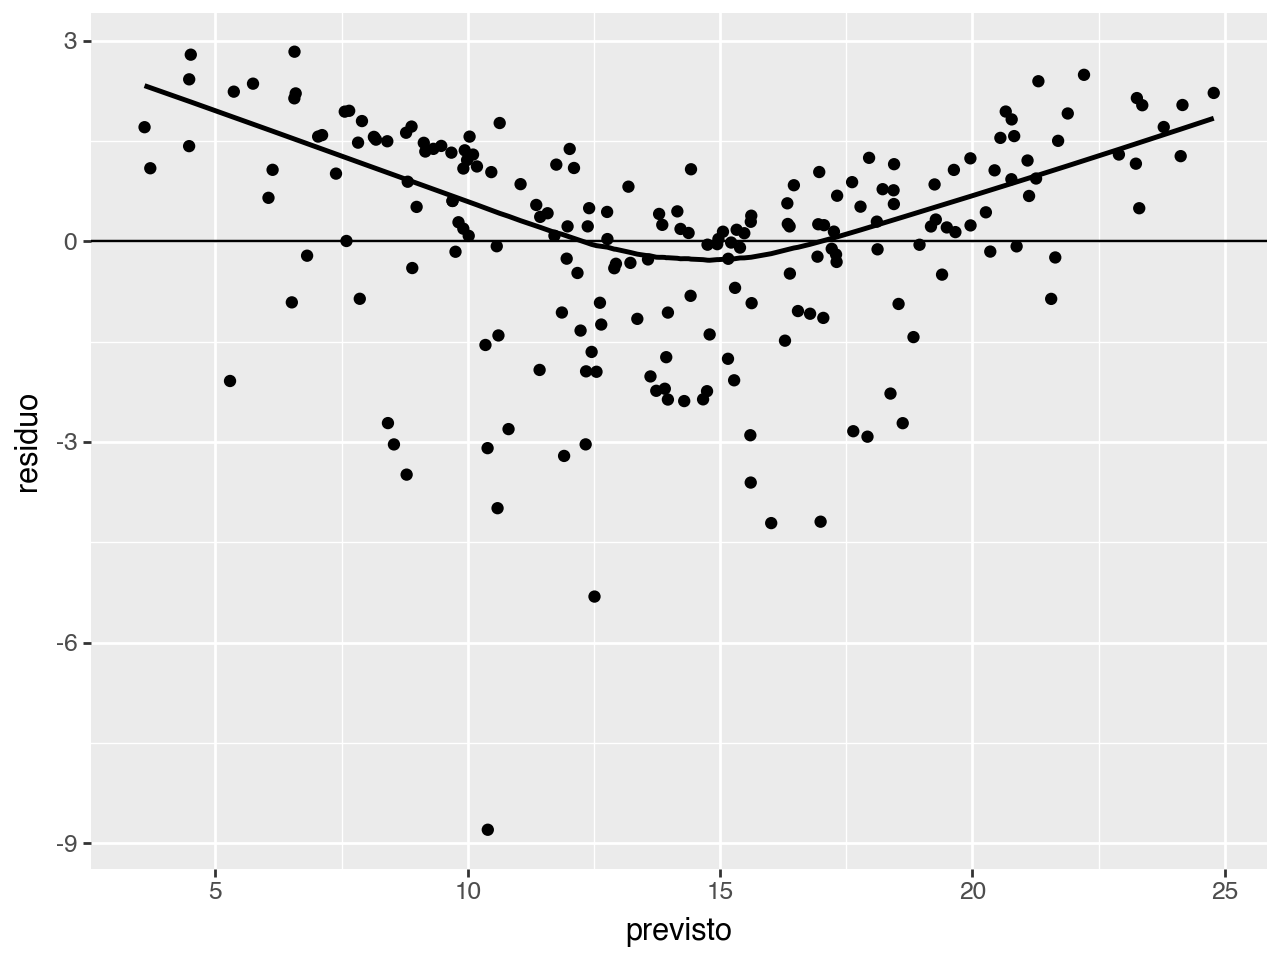

In [15]:
res = pl.DataFrame({"previsto": senza.fittedvalues, "residuo": senza.resid})
ggplot(res, aes(x="previsto", y="residuo")) + geom_point() + geom_hline(yintercept=0) + geom_smooth()

In [16]:
sinergia = smf.ols("sales ~ TV * radio", data=adv.to_pandas()).fit()
sinergia.params, sinergia.rsquared

(Intercept    6.750220
 TV           0.019101
 radio        0.028860
 TV:radio     0.001086
 dtype: float64,
 0.9677905498482523)